# ERIC — Module 6a: Image-Only Transformer Captioning Baseline

## Project context

**ERIC** investigates edge-aware raster-guided image captioning for remote-sensing imagery. Module 6a establishes the conventional **image-only Transformer captioning baseline** against which raster-only and image–raster methods will later be compared.

### Research question

How well can a Transformer captioning model describe remote-sensing images when it receives only the original image and no semantic raster?

### Module 6a scope

- **Input:** RGB remote-sensing image.
- **Visual encoder:** ImageNet-pretrained ViT-Base/16.
- **Text decoder:** Transformer decoder trained from scratch.
- **Encoder adaptation:** Freeze most ViT parameters; fine-tune the final two Transformer blocks and final normalization layer.
- **Caption supervision:** Five human-written RSICD captions per image during training.
- **Excluded:** Semantic raster input, raster-derived supervision, and raster/image fusion.

This notebook uses the eight selected scene classes: `airport`, `baseballfield`, `beach`, `mediumresidential`, `pond`, `river`, `sparseresidential`, and `stadium`.

> **Reproducibility note:** Run the notebook from top to bottom in the configured Kaggle environment. The dataset paths are environment-specific. Training creates checkpoints under `/kaggle/working/ERIC_Module6a`; generated predictions and metric files are saved there as well.


## 1. Theory: image captioning with a Transformer

Image captioning is a conditional sequence-generation task. Given an image \(I\), the model predicts a word sequence \(Y=(y_1, y_2, \ldots, y_T)\) that describes the image.

The model factorizes the caption probability autoregressively:

\[
P(Y\mid I)=\prod_{t=1}^{T}P(y_t\mid y_{<t}, I)
\]

At each decoding step, the decoder uses previously generated tokens and visual features from the image to predict the next token.

### Why this is a baseline

A standard image-only captioner tests what can be achieved using visual features and natural-language generation alone. Because Module 6a does not receive a raster, later improvements in Modules 6b and 6e can be evaluated against this baseline to measure the value of semantic raster information.


## 2. Experimental design and data integrity

RSICD provides image-level official `train`, `val`, and `test` splits. This notebook filters those records to the eight selected scene classes using the dataset's class text files.

Each selected image is expected to have five reference captions. Training expands each training image into five image–caption examples, but **the image split is performed before caption expansion**. This prevents captions from the same image from leaking across splits.

### Dataset checks performed

- The image JSON is indexed by filename.
- Scene membership comes from the selected class text files.
- Official split names are retained.
- Selected image filenames must not overlap across train, validation, and test.
- Each retained image must have exactly five captions.
- Image files must exist on disk.

The exact selected-split counts are printed by the notebook when it runs. Do not assume full-dataset counts apply to the eight-class subset.


In [1]:
import os
import json
import random
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter

## 3. Reproducibility, paths, and configuration

The following cells set random seeds, configure dataset locations, define the selected classes, and validate that the expected data is available. Keep these paths and settings with the experiment record so the baseline can be reproduced.


In [2]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [3]:
# Dataset paths
IMG_DIR = Path(
    "/kaggle/input/datasets/vedantbarhate007/"
    "rsicd-eric/RSICD_optimal-master/RSICD_images"
)

DATASET_JSON = Path(
    "/kaggle/input/datasets/vedantbarhate007/"
    "rsicd-eric/RSICD_optimal-master/dataset_rsicd.json"
)

BASE_DIR = DATASET_JSON.parent

In [4]:

# The only eight scene classes permitted in Module 6a
SELECTED_CLASSES = {
    "airport",
    "baseballfield",
    "beach",
    "mediumresidential",
    "pond",
    "river",
    "sparseresidential",
    "stadium",
}

In [5]:
# Model configuration
IMAGE_SIZE = 224
PATCH_SIZE = 16
MAX_CAPTIONS_PER_IMAGE = 5

# Check paths
assert IMG_DIR.is_dir(), f"Image directory not found: {IMG_DIR}"
assert DATASET_JSON.is_file(), f"Dataset JSON not found: {DATASET_JSON}"

print("Dataset paths verified.")
print("Image directory:", IMG_DIR)
print("Dataset JSON:", DATASET_JSON)
print("Selected classes:", sorted(SELECTED_CLASSES))
print("Number of selected classes:", len(SELECTED_CLASSES))
print("Image files found:", sum(1 for p in IMG_DIR.iterdir() if p.is_file()))

Dataset paths verified.
Image directory: /kaggle/input/datasets/vedantbarhate007/rsicd-eric/RSICD_optimal-master/RSICD_images
Dataset JSON: /kaggle/input/datasets/vedantbarhate007/rsicd-eric/RSICD_optimal-master/dataset_rsicd.json
Selected classes: ['airport', 'baseballfield', 'beach', 'mediumresidential', 'pond', 'river', 'sparseresidential', 'stadium']
Number of selected classes: 8
Image files found: 10921


## 4. Load and filter the RSICD dataset

The JSON provides image filenames, official split labels, and five caption sentences per image. Scene class membership is loaded from `txtclasses_rsicd`. The filtering code builds image-level records and verifies that the resulting split lists are disjoint.


In [6]:
with open(DATASET_JSON, "r", encoding="utf-8") as f:
    rsicd_data = json.load(f)

print("Root keys:", list(rsicd_data.keys()))
image_records = rsicd_data.get("images", [])
print("Total image records:", len(image_records))

if image_records:
    sample = image_records[0]
    print("\nFirst image record keys:", list(sample.keys()))
    print("\nFilename:", sample.get("filename"))
    print("Image ID:", sample.get("imgid"))
    print("Split:", sample.get("split"))

    sentences = sample.get("sentences", [])
    print("Number of captions:", len(sentences))

    for i, sentence in enumerate(sentences, start=1):
        print(f"Caption {i}:", sentence.get("raw"))

Root keys: ['images', 'dataset']
Total image records: 10921

First image record keys: ['filename', 'imgid', 'sentences', 'split', 'sentids']

Filename: airport_1.jpg
Image ID: 0
Split: train
Number of captions: 5
Caption 1: many planes are parked next to a long building in an airport .
Caption 2: many planes are parked next to a long building in an airport .
Caption 3: many planes are parked next to a long building in an airport .
Caption 4: many planes are parked next to a long building in an airport .
Caption 5: many planes are parked next to a long building in an airport .


In [7]:
split_counts = Counter(
    str(record.get("split", "")).strip().lower()
    for record in image_records
)

print("Official split counts:")
for split, count in sorted(split_counts.items()):
    print(f"{split}: {count}")

print("\nExample filenames by split:")
for split in ("train", "val", "test"):
    examples = [
        r.get("filename")
        for r in image_records
        if str(r.get("split", "")).strip().lower() == split
    ]
    print(f"{split}: {examples[:5]}")

Official split counts:
test: 1093
train: 8734
val: 1094

Example filenames by split:
train: ['airport_1.jpg', 'airport_10.jpg', 'airport_100.jpg', 'airport_101.jpg', 'airport_102.jpg']
val: ['airport_61.jpg', 'airport_62.jpg', 'airport_63.jpg', 'airport_64.jpg', 'airport_65.jpg']
test: ['airport_348.jpg', 'airport_349.jpg', 'airport_35.jpg', 'airport_350.jpg', 'airport_351.jpg']


In [8]:
from pathlib import Path

CLASSES_DIR = Path(
    "/kaggle/input/datasets/vedantbarhate007/"
    "rsicd-eric/RSICD_optimal-master/txtclasses_rsicd"
)

assert CLASSES_DIR.is_dir(), f"Directory not found: {CLASSES_DIR}"

# Map lowercase class-file stems to their actual paths
class_file_map = {
    path.stem.lower(): path
    for path in CLASSES_DIR.glob("*.txt")
}

# Load the eight selected classes
scene_to_images = {}

for scene in sorted(SELECTED_CLASSES):
    if scene not in class_file_map:
        raise FileNotFoundError(
            f"No class file found for '{scene}'. "
            f"Available classes: {sorted(class_file_map)}"
        )

    class_file = class_file_map[scene]

    with open(class_file, "r", encoding="utf-8-sig") as f:
        filenames = {
            line.strip()
            for line in f
            if line.strip()
        }

    scene_to_images[scene] = filenames

    print(
        f"{scene:20s}: {len(filenames):5d} images "
        f"({class_file.name})"
    )

print("\nSuccessfully loaded all eight class files.")
print("Total unique image names:",
      len(set().union(*scene_to_images.values())))

airport             :   420 images (Airport.txt)
baseballfield       :   276 images (BaseballField.txt)
beach               :   400 images (Beach.txt)
mediumresidential   :   290 images (MediumResidential.txt)
pond                :   420 images (Pond.txt)
river               :   410 images (River.txt)
sparseresidential   :   300 images (SparseResidential.txt)
stadium             :   290 images (Stadium.txt)

Successfully loaded all eight class files.
Total unique image names: 2806


In [9]:
# Build authoritative image-to-scene mapping
image_to_scene = {}

for scene, filenames in scene_to_images.items():
    for filename in filenames:
        if filename in image_to_scene:
            raise ValueError(
                f"{filename} appears in multiple selected classes: "
                f"{image_to_scene[filename]} and {scene}"
            )
        image_to_scene[filename] = scene

# Index the JSON records by filename
json_by_filename = {
    record["filename"]: record
    for record in image_records
}

filtered_records = []
class_file_names_missing_from_json = []

for filename, scene in image_to_scene.items():
    record = json_by_filename.get(filename)

    if record is None:
        class_file_names_missing_from_json.append(filename)
        continue

    captions = [
        str(sentence.get("raw", "")).strip()
        for sentence in record.get("sentences", [])
        if sentence.get("raw")
    ]

    split = str(record.get("split", "")).strip().lower()

    if split not in {"train", "val", "test"}:
        raise ValueError(
            f"Unexpected split {split!r} for {filename}"
        )

    filtered_records.append({
        "filename": filename,
        "imgid": record.get("imgid"),
        "scene": scene,
        "split": split,
        "captions": captions,
    })

print("Selected class-file image names:", len(image_to_scene))
print("Matched JSON records:", len(filtered_records))
print("Class-file names missing from JSON:",
      len(class_file_names_missing_from_json))
print("Missing examples:", class_file_names_missing_from_json[:10])

print("\nImages by scene:")
for scene in sorted(SELECTED_CLASSES):
    count = sum(r["scene"] == scene for r in filtered_records)
    print(f"{scene:20s}: {count}")

print("\nImages by official split:")
for split in ("train", "val", "test"):
    count = sum(r["split"] == split for r in filtered_records)
    print(f"{split:6s}: {count}")

print("\nTotal image-caption pairs:",
      sum(len(r["captions"]) for r in filtered_records))

Selected class-file image names: 2806
Matched JSON records: 2806
Class-file names missing from JSON: 0
Missing examples: []

Images by scene:
airport             : 420
baseballfield       : 276
beach               : 400
mediumresidential   : 290
pond                : 420
river               : 410
sparseresidential   : 300
stadium             : 290

Images by official split:
train : 2244
val   : 281
test  : 281

Total image-caption pairs: 14030


In [10]:
split_sets = {
    split: {
        r["filename"]
        for r in filtered_records
        if r["split"] == split
    }
    for split in ("train", "val", "test")
}

assert split_sets["train"].isdisjoint(split_sets["val"])
assert split_sets["train"].isdisjoint(split_sets["test"])
assert split_sets["val"].isdisjoint(split_sets["test"])

missing_images = [
    r["filename"]
    for r in filtered_records
    if not (IMG_DIR / r["filename"]).is_file()
]

caption_counts = Counter(len(r["captions"]) for r in filtered_records)

print("Caption-count distribution:", dict(sorted(caption_counts.items())))
print("Missing image files:", len(missing_images))
print("Train/validation/test overlap: none")

assert not missing_images, f"Missing images: {missing_images[:10]}"
assert all(len(r["captions"]) == 5 for r in filtered_records), (
    "Some images do not have exactly five captions; inspect the "
    "caption-count distribution before proceeding."
)

print("\nAll checks passed.")

Caption-count distribution: {5: 2806}
Missing image files: 0
Train/validation/test overlap: none

All checks passed.


In [11]:
# Convert filtered records into image-level split lists
train_records = [r for r in filtered_records if r["split"] == "train"]
val_records   = [r for r in filtered_records if r["split"] == "val"]
test_records  = [r for r in filtered_records if r["split"] == "test"]

# Expand training images into image-caption pairs
train_pairs = [
    {
        "filename": r["filename"],
        "scene": r["scene"],
        "caption": caption,
    }
    for r in train_records
    for caption in r["captions"]
]

print("Image-level split counts")
print(f"Train:      {len(train_records):,} images")
print(f"Validation: {len(val_records):,} images")
print(f"Test:       {len(test_records):,} images")

print("\nTraining examples")
print(f"Training image-caption pairs: {len(train_pairs):,}")

print("\nExample training pairs:")
for pair in train_pairs[:3]:
    print(pair)

# Verify that every training image contributes five captions
assert all(len(r["captions"]) == 5 for r in train_records), (
    "At least one training image does not have five captions."
)

assert len(train_pairs) == len(train_records) * 5

# Verify image-level splits remain disjoint
train_names = {r["filename"] for r in train_records}
val_names   = {r["filename"] for r in val_records}
test_names  = {r["filename"] for r in test_records}

assert train_names.isdisjoint(val_names)
assert train_names.isdisjoint(test_names)
assert val_names.isdisjoint(test_names)

print("\nAll training-pair and split checks passed.")

Image-level split counts
Train:      2,244 images
Validation: 281 images
Test:       281 images

Training examples
Training image-caption pairs: 11,220

Example training pairs:
{'filename': 'airport_304.jpg', 'scene': 'airport', 'caption': 'many of the planes were docked on the wide .'}
{'filename': 'airport_304.jpg', 'scene': 'airport', 'caption': 'a white big plane are on the runway .'}
{'filename': 'airport_304.jpg', 'scene': 'airport', 'caption': 'two planes are parked next to two terminal respectively in an airport .'}

All training-pair and split checks passed.


## 5. Caption preprocessing and vocabulary

Captions are lowercased, whitespace is normalized, and spaces are inserted around common punctuation. A word-level vocabulary is built **from training captions only** to avoid using validation or test text to construct the vocabulary.

Special tokens:

| Token | Purpose |
|---|---|
| `<pad>` | Pads sequences to a common batch length; ignored by the loss |
| `<unk>` | Represents a word not in the training vocabulary |
| `<bos>` | Marks the beginning of a caption |
| `<eos>` | Marks the end of a caption |

Teacher forcing shifts the token sequence: the decoder receives the caption prefix and is trained to predict the next token. The maximum caption length is 64 tokens, including special tokens.


In [12]:
import re
from collections import Counter

def preprocess_caption(text):
    text = text.lower().strip()

    # Normalize spacing around common punctuation
    text = re.sub(r"([.,!?])", r" \1 ", text)

    # Collapse repeated whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


def tokenize_caption(text):
    text = preprocess_caption(text)
    return text.split()


# Special tokens
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
BOS_TOKEN = "<bos>"
EOS_TOKEN = "<eos>"

SPECIAL_TOKENS = [PAD_TOKEN, UNK_TOKEN, BOS_TOKEN, EOS_TOKEN]

PAD_IDX = 0
UNK_IDX = 1
BOS_IDX = 2
EOS_IDX = 3

# Build vocabulary from training captions only
token_counts = Counter()

for pair in train_pairs:
    token_counts.update(tokenize_caption(pair["caption"]))

MIN_WORD_FREQ = 1

vocab_tokens = sorted(
    token for token, count in token_counts.items()
    if count >= MIN_WORD_FREQ
)

itos = SPECIAL_TOKENS + [
    token for token in vocab_tokens
    if token not in SPECIAL_TOKENS
]

stoi = {token: idx for idx, token in enumerate(itos)}
VOCAB_SIZE = len(itos)

print("Vocabulary size:", VOCAB_SIZE)
print("Example tokens:", tokenize_caption(train_pairs[0]["caption"]))

Vocabulary size: 1098
Example tokens: ['many', 'of', 'the', 'planes', 'were', 'docked', 'on', 'the', 'wide', '.']


In [13]:
def encode_caption(text):
    token_ids = [
        stoi.get(token, UNK_IDX)
        for token in tokenize_caption(text)
    ]
    return [BOS_IDX] + token_ids + [EOS_IDX]


def decode_caption(token_ids):
    tokens = []
    for token_id in token_ids:
        if token_id == EOS_IDX:
            break
        if token_id in (PAD_IDX, BOS_IDX):
            continue
        if 0 <= token_id < len(itos):
            tokens.append(itos[token_id])

    return " ".join(tokens)


# Verify normalized round-trip equality
for pair in train_pairs[:10]:
    original = preprocess_caption(pair["caption"])
    encoded = encode_caption(pair["caption"])
    decoded = decode_caption(encoded)

    assert decoded == original, (
        f"\nOriginal: {original!r}"
        f"\nDecoded:  {decoded!r}"
    )

    print("PASS:", decoded)

print("\nAll tokenizer round-trip checks passed.")

PASS: many of the planes were docked on the wide .
PASS: a white big plane are on the runway .
PASS: two planes are parked next to two terminal respectively in an airport .
PASS: two planes are parked next to two terminal respectively in an airport .
PASS: many of the planes were docked on the wide .
PASS: some planes are parked in an airport .
PASS: the airport here is full of airplanes and containers .
PASS: the airport here is full of airplanes and containers .
PASS: some planes are parked in an airport .
PASS: some planes are parked in an airport .

All tokenizer round-trip checks passed.


## 6. Visual encoder: ImageNet-pretrained ViT-Base/16

The image is resized to 224 × 224 and normalized using ImageNet statistics. ViT-Base/16 divides it into non-overlapping 16 × 16 patches, producing a 14 × 14 grid, or 196 patch tokens, plus a class (CLS) token.

The CLS token is removed before the decoder receives the visual sequence. Each patch token has 768 dimensions.

### Transfer-learning strategy

The encoder starts from ImageNet-pretrained weights. Most parameters remain frozen, while the final two Transformer blocks and final normalization layer are trainable. This limits the number of trainable parameters and allows high-level visual representations to adapt to remote-sensing imagery.

The model is an ImageNet-pretrained ViT, **not a remote-sensing-pretrained encoder**.


In [14]:
import torch
import torch.nn as nn
import timm
import torchvision
from torchvision import transforms
from PIL import Image

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
    print(
        "GPU memory (GB):",
        round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)
    )
else:
    print("GPU unavailable. In Kaggle, enable GPU under Notebook Settings.")

assert torch.cuda.is_available(), (
    "Enable a Kaggle GPU before proceeding with model training."
)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
timm: 1.0.29

Device: cuda
GPU: Tesla T4
GPU count: 2
GPU memory (GB): 15.64


In [15]:
# Load pretrained ViT-Base/16
encoder = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True,
    num_classes=0,  # Remove ImageNet classification head
)

encoder = encoder.to(device)

# Freeze the entire encoder first
for param in encoder.parameters():
    param.requires_grad = False

# Unfreeze the final two Transformer blocks
for block in encoder.blocks[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep the final normalization layer trainable
for param in encoder.norm.parameters():
    param.requires_grad = True

total_params = sum(p.numel() for p in encoder.parameters())
trainable_params = sum(
    p.numel() for p in encoder.parameters() if p.requires_grad
)

print("Encoder:", type(encoder).__name__)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Trainable percentage:", f"{100 * trainable_params / total_params:.2f}%")
print("Transformer blocks:", len(encoder.blocks))
print("Unfrozen blocks: final two")

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Encoder: VisionTransformer
Total parameters: 85,798,656
Trainable parameters: 14,177,280
Trainable percentage: 16.52%
Transformer blocks: 12
Unfrozen blocks: final two


In [16]:
# Standard ImageNet normalization
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
])

sample_path = IMG_DIR / train_records[0]["filename"]

with Image.open(sample_path) as image:
    image = image.convert("RGB")
    sample_tensor = image_transform(image).unsqueeze(0).to(device)

encoder.eval()

with torch.no_grad():
    features = encoder.forward_features(sample_tensor)

print("Input shape:", tuple(sample_tensor.shape))
print("Encoder output shape:", tuple(features.shape))
print("Feature dtype:", features.dtype)
print("Feature device:", features.device)

assert features.shape == (1, 197, 768), (
    f"Unexpected encoder output shape: {features.shape}"
)

print("Encoder feature check passed.")

Input shape: (1, 3, 224, 224)
Encoder output shape: (1, 197, 768)
Feature dtype: torch.float32
Feature device: cuda:0
Encoder feature check passed.


## 7. Text decoder: Transformer with causal self-attention and visual cross-attention

The decoder uses the following components:

1. **Token embedding:** maps each caption token to a 512-dimensional vector.
2. **Learned positional embedding:** represents token order.
3. **Visual projection:** projects 768-dimensional ViT patch features to the decoder's 512-dimensional hidden space.
4. **Causal self-attention:** prevents a token from attending to future caption tokens.
5. **Cross-attention:** lets the text decoder attend to all 196 visual patch tokens.
6. **Output projection:** maps decoder states to vocabulary logits for next-token prediction.

### Decoder configuration

| Parameter | Value |
|---|---:|
| Hidden dimension (`d_model`) | 512 |
| Attention heads | 8 |
| Decoder layers | 3 |
| Feed-forward dimension | 2048 |
| Dropout | 0.1 |
| Maximum caption length | 64 tokens |

The decoder is randomly initialized and trained on the RSICD caption data. Its three-layer configuration is also recorded in the checkpoint metadata.


In [17]:
import torch
import torch.nn as nn
import math


class PositionalEncoding(nn.Module):
    """Learned positional embeddings for caption tokens."""
    def __init__(self, max_len, d_model):
        super().__init__()
        self.embedding = nn.Embedding(max_len, d_model)

    def forward(self, x):
        # x: [batch, sequence_length, d_model]
        positions = torch.arange(
            x.size(1), device=x.device
        ).unsqueeze(0)

        return x + self.embedding(positions)


class TransformerCaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=512,
        nhead=8,
        num_layers=6,
        dim_feedforward=2048,
        dropout=0.2,
        max_caption_len=64,
        encoder_dim=768,
        pad_idx=PAD_IDX,
    ):
        super().__init__()

        self.d_model = d_model
        self.pad_idx = pad_idx

        self.token_embedding = nn.Embedding(
            vocab_size, d_model, padding_idx=pad_idx
        )
        self.position_encoding = PositionalEncoding(
            max_caption_len, d_model
        )

        self.encoder_projection = nn.Linear(encoder_dim, d_model)

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=False,
        )

        self.transformer_decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(d_model),
        )

        self.output_layer = nn.Linear(d_model, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, image_features, caption_input):
        """
        image_features: [B, 196, 768]
        caption_input:  [B, T] (includes BOS, excludes target shift)
        returns:        [B, T, vocab_size]
        """
        batch_size, seq_len = caption_input.shape

        # Project image tokens to decoder dimension
        memory = self.encoder_projection(image_features)

        # Embed caption input tokens
        target = self.token_embedding(caption_input)
        target = target * math.sqrt(self.d_model)
        target = self.position_encoding(target)
        target = self.dropout(target)

        # True values indicate positions that cannot be attended to
        causal_mask = torch.triu(
            torch.ones(
                seq_len, seq_len,
                dtype=torch.bool,
                device=caption_input.device,
            ),
            diagonal=1,
        )

        target_padding_mask = caption_input.eq(self.pad_idx)

        decoded = self.transformer_decoder(
            tgt=target,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=target_padding_mask,
        )

        return self.output_layer(decoded)

In [18]:
decoder = TransformerCaptionDecoder(
    vocab_size=VOCAB_SIZE,
    d_model=512,
    nhead=8,
    num_layers=3,
    dim_feedforward=2048,
    dropout=0.1,
    max_caption_len=64,
    encoder_dim=768,
    pad_idx=PAD_IDX,
).to(device)

print(decoder)

decoder_params = sum(p.numel() for p in decoder.parameters())
print(f"\nDecoder parameters: {decoder_params:,}")

TransformerCaptionDecoder(
  (token_embedding): Embedding(1098, 512, padding_idx=0)
  (position_encoding): PositionalEncoding(
    (embedding): Embedding(64, 512)
  )
  (encoder_projection): Linear(in_features=768, out_features=512, bias=True)
  (transformer_decoder): TransformerDecoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerDecoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (multihead_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (linear1): Linear(in_features=512, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=512, bias=True)
        (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)

In [19]:
# Spatial tokens only: remove ViT's CLS token
encoder.eval()
decoder.eval()

with torch.no_grad():
    image_features = encoder.forward_features(sample_tensor)
    image_features = image_features[:, 1:, :]

    dummy_caption = torch.tensor(
        [[BOS_IDX, stoi.get("a", UNK_IDX), EOS_IDX]],
        dtype=torch.long,
        device=device,
    )

    logits = decoder(image_features, dummy_caption)

print("Image features:", tuple(image_features.shape))
print("Decoder input:", tuple(dummy_caption.shape))
print("Output logits:", tuple(logits.shape))

assert image_features.shape == (1, 196, 768)
assert logits.shape == (1, 3, VOCAB_SIZE)

print("Encoder-decoder connection check passed.")

Image features: (1, 196, 768)
Decoder input: (1, 3)
Output logits: (1, 3, 1098)
Encoder-decoder connection check passed.


## 8. Dataset and data loaders

The training dataset contains one item per image–caption pair. Therefore, an image with five references contributes five training examples. Validation and test records remain image-level records so that generated captions can be compared against all five references.

The data-loader checks confirm tensor dimensions and show a decoded training caption before model training begins.


In [20]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from functools import partial

# Keep batches manageable for a Kaggle GPU.
BATCH_SIZE = 32
NUM_WORKERS = 2
MAX_CAPTION_LEN = 64


class RSICDTrainDataset(Dataset):
    """
    Each item is one image-caption pair.
    An image with five captions contributes five training items.
    """
    def __init__(self, records, image_dir, transform, max_caption_len=64):
        self.image_dir = Path(image_dir)
        self.transform = transform
        self.max_caption_len = max_caption_len

        self.samples = [
            (record["filename"], caption)
            for record in records
            for caption in record["captions"]
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        filename, caption = self.samples[idx]
        image_path = self.image_dir / filename

        with Image.open(image_path) as img:
            image = self.transform(img.convert("RGB"))

        token_ids = encode_caption(caption)[:self.max_caption_len]

        # Ensure EOS is retained after truncation.
        if token_ids[-1] != EOS_IDX:
            token_ids[-1] = EOS_IDX

        return image, torch.tensor(token_ids, dtype=torch.long)


class RSICDEvalDataset(Dataset):
    """
    One item per image, retaining all five reference captions.
    """
    def __init__(self, records, image_dir, transform):
        self.records = records
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        with Image.open(self.image_dir / record["filename"]) as img:
            image = self.transform(img.convert("RGB"))

        return {
            "image": image,
            "filename": record["filename"],
            "references": record["captions"],
            "scene": record["scene"],
        }


def collate_train(batch, pad_idx=PAD_IDX):
    images, captions = zip(*batch)

    images = torch.stack(images)
    captions = torch.nn.utils.rnn.pad_sequence(
        captions,
        batch_first=True,
        padding_value=pad_idx,
    )

    return images, captions


def collate_eval(batch):
    return {
        "images": torch.stack([item["image"] for item in batch]),
        "filenames": [item["filename"] for item in batch],
        "references": [item["references"] for item in batch],
        "scenes": [item["scene"] for item in batch],
    }


train_dataset = RSICDTrainDataset(
    train_records, IMG_DIR, image_transform, MAX_CAPTION_LEN
)

val_dataset = RSICDEvalDataset(
    val_records, IMG_DIR, image_transform
)

test_dataset = RSICDEvalDataset(
    test_records, IMG_DIR, image_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=partial(collate_train, pad_idx=PAD_IDX),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_eval,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_eval,
)

print("Training pairs:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Training batches per epoch:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training pairs: 11220
Validation images: 281
Test images: 281
Training batches per epoch: 351
Validation batches: 9
Test batches: 9


In [21]:
images, captions = next(iter(train_loader))

print("Training images shape:", tuple(images.shape))
print("Training captions shape:", tuple(captions.shape))
print("Caption example IDs:", captions[0].tolist())
print("Decoded caption:", decode_caption(captions[0].tolist()))

eval_batch = next(iter(val_loader))

print("\nValidation images shape:", tuple(eval_batch["images"].shape))
print("First filename:", eval_batch["filenames"][0])
print("Reference count:", len(eval_batch["references"][0]))
print("References:", eval_batch["references"][0])

assert images.ndim == 4 and images.shape[1:] == (3, 224, 224)
assert captions.ndim == 2
assert len(eval_batch["references"][0]) == 5

print("\nDataLoader checks passed.")

Training images shape: (32, 3, 224, 224)
Training captions shape: (32, 19)
Caption example IDs: [2, 6, 83, 462, 566, 6, 648, 587, 244, 402, 5, 3, 0, 0, 0, 0, 0, 0, 0]
Decoded caption: a beach is near a piece of dark green .

Validation images shape: (32, 3, 224, 224)
First filename: airport_65.jpg
Reference count: 5
References: ['the ploygon terminal building is built near road and other buildings  on the other side of which is tarmac and runways .', 'the ploygon terminal building is built near road and other buildings  on the other side of which is tarmac and runways .', 'the alternation runway next to a bright blue parking aroneng .', 'a dazzling apron is surrounded by the termial building and six block of houses and two runway .', 'a plane is on the runway while other two planes are near some buildings and green plants .']

DataLoader checks passed.


## 9. Training objective and optimization

The model is trained with token-level cross-entropy loss under teacher forcing. Padding positions are excluded from the loss.

\[
\mathcal{L}_{\mathrm{CE}}=-\frac{1}{N}\sum_{t\in\mathrm{valid}}\log P(y_t\mid y_{<t},I)
\]

where the valid positions exclude `<pad>` tokens.

### Optimization settings

| Setting | Value |
|---|---:|
| Epochs | 5 |
| Encoder learning rate | 5 × 10⁻⁵ |
| Decoder learning rate | 1 × 10⁻⁴ |
| Weight decay | 1 × 10⁻⁴ |
| Gradient clipping | 1.0 |
| Batch size | 32 |
| Mixed precision | Enabled when CUDA is available |
| Checkpoint selection | Lowest epoch-level validation loss |

Separate learning rates are used because the pretrained encoder is being adapted, while the decoder is trained from scratch. The encoder's frozen blocks remain in evaluation mode during training to avoid stochastic behavior from frozen layers.

**Validation-loss detail:** epoch-level validation loss uses the first reference caption per image as a checkpoint-selection signal. A separate diagnostic later computes train and validation loss over all five references for a comparable diagnostic. Caption-generation metrics use all five references.


In [22]:
import os
import math
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.amp import autocast, GradScaler

# Training configuration
NUM_EPOCHS = 5
ENCODER_LR = 5e-5
DECODER_LR = 1e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 1.0

OUTPUT_DIR = "/kaggle/working/ERIC_Module6a"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_CHECKPOINT_PATH = os.path.join(
    OUTPUT_DIR, "module6a_best.pt"
)
LAST_CHECKPOINT_PATH = os.path.join(
    OUTPUT_DIR, "module6a_last.pt"
)

# Separate learning rates for pretrained encoder and new decoder
encoder_trainable_params = [
    p for p in encoder.parameters() if p.requires_grad
]

decoder_params = list(decoder.parameters())

optimizer = AdamW(
    [
        {"params": encoder_trainable_params, "lr": ENCODER_LR},
        {"params": decoder_params, "lr": DECODER_LR},
    ],
    weight_decay=WEIGHT_DECAY,
)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

# Mixed precision on CUDA
scaler = GradScaler("cuda", enabled=(device.type == "cuda"))

print("Output directory:", OUTPUT_DIR)
print("Epochs:", NUM_EPOCHS)
print("Encoder LR:", ENCODER_LR)
print("Decoder LR:", DECODER_LR)
print("Mixed precision:", device.type == "cuda")

Output directory: /kaggle/working/ERIC_Module6a
Epochs: 5
Encoder LR: 5e-05
Decoder LR: 0.0001
Mixed precision: True


In [23]:
def set_encoder_mode_for_training(encoder, training):
    # Start with all encoder modules in evaluation mode.
    encoder.eval()

    if training:
        # Only the final two blocks are fine-tuned.
        for block in encoder.blocks[-2:]:
            block.train()

        # The final normalization layer is also trainable.
        encoder.norm.train()

In [24]:
def run_epoch(model_encoder, model_decoder, loader, training):
    set_encoder_mode_for_training(model_encoder, training)
    model_decoder.train(training)

    total_loss = 0.0
    total_tokens = 0

    for batch in loader:

        # Training loader returns (images, captions)
        if training:
            images, captions = batch

        # Validation loader returns a dictionary
        else:
            images = batch["images"]

            # Use the first reference caption for epoch-level validation loss.
            # Validation loss is a checkpoint-selection signal;
            # final caption metrics will use all five references.
            captions = [
                refs[0] for refs in batch["references"]
            ]

            encoded = [
                encode_caption(caption)[:MAX_CAPTION_LEN]
                for caption in captions
            ]

            # Ensure EOS remains the final token after truncation
            for seq in encoded:
                if seq[-1] != EOS_IDX:
                    seq[-1] = EOS_IDX

            captions = torch.nn.utils.rnn.pad_sequence(
                [
                    torch.tensor(seq, dtype=torch.long)
                    for seq in encoded
                ],
                batch_first=True,
                padding_value=PAD_IDX,
            )

        images = images.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)

        caption_input = captions[:, :-1]
        targets = captions[:, 1:]

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda"),
            ):
                image_features = model_encoder.forward_features(images)
                image_features = image_features[:, 1:, :]  # remove CLS

                logits = model_decoder(image_features, caption_input)

                loss = criterion(
                    logits.reshape(-1, logits.size(-1)),
                    targets.reshape(-1),
                )

            if training:
                scaler.scale(loss).backward()

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    [
                        p for p in model_encoder.parameters()
                        if p.requires_grad
                    ] + [
                        p for p in model_decoder.parameters()
                        if p.requires_grad
                    ],
                    GRAD_CLIP_NORM,
                )

                scaler.step(optimizer)
                scaler.update()

        valid_tokens = targets.ne(PAD_IDX).sum().item()
        total_loss += loss.detach().item() * valid_tokens
        total_tokens += valid_tokens

    return total_loss / max(total_tokens, 1)

## 10. Training history and checkpoint selection

The training cell saves both the latest checkpoint and the checkpoint with the lowest validation loss. The training-history table and plot help diagnose optimization behavior.

### Recorded run

| Epoch | Training loss | Validation loss |
|---:|---:|---:|
| 1 | 2.1067 | 2.5410 |
| 2 | 1.2041 | 2.6079 |
| 3 | 0.8372 | 2.6132 |
| 4 | 0.6158 | 2.7424 |
| 5 | 0.4747 | 2.8886 |

**Best checkpoint:** epoch 1, validation loss 2.5410.

Training loss falls at every epoch while validation loss rises after epoch 1. This is consistent with overfitting: the model continues fitting training captions without improving its epoch-level validation loss. Consequently, the best-validation-loss checkpoint is used for caption generation and evaluation.


In [25]:
from tqdm.auto import tqdm

history = []
best_val_loss = float("inf")

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = run_epoch(
        encoder, decoder, train_loader, training=True
    )

    val_loss = run_epoch(
        encoder, decoder, val_loader, training=False
    )

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
    }
    history.append(record)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f}"
    )

    checkpoint = {
        "epoch": epoch,
        "encoder_state_dict": encoder.state_dict(),
        "decoder_state_dict": decoder.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "vocab": itos,
        "config": {
            "selected_classes": sorted(SELECTED_CLASSES),
            "image_size": IMAGE_SIZE,
            "patch_size": PATCH_SIZE,
            "d_model": 512,
            "nhead": 8,
            "num_decoder_layers": 3,
            "max_caption_len": MAX_CAPTION_LEN,
        },
        "history": history,
        "val_loss": val_loss,
    }

    torch.save(checkpoint, LAST_CHECKPOINT_PATH)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(checkpoint, BEST_CHECKPOINT_PATH)
        print("  Saved new best checkpoint.")

print("\nTraining complete.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best checkpoint:", BEST_CHECKPOINT_PATH)
print("Last checkpoint:", LAST_CHECKPOINT_PATH)

Epoch 01/5 | Train loss: 2.1006 | Val loss: 2.5385
  Saved new best checkpoint.
Epoch 02/5 | Train loss: 1.2148 | Val loss: 2.5859
Epoch 03/5 | Train loss: 0.8434 | Val loss: 2.6646
Epoch 04/5 | Train loss: 0.6174 | Val loss: 2.7646
Epoch 05/5 | Train loss: 0.4825 | Val loss: 2.8211

Training complete.
Best validation loss: 2.5385
Best checkpoint: /kaggle/working/ERIC_Module6a/module6a_best.pt
Last checkpoint: /kaggle/working/ERIC_Module6a/module6a_last.pt


,epoch,train_loss,val_loss
0,1,2.100614,2.538534
1,2,1.214814,2.585947
2,3,0.843373,2.664557
3,4,0.617397,2.764592
4,5,0.482517,2.821145


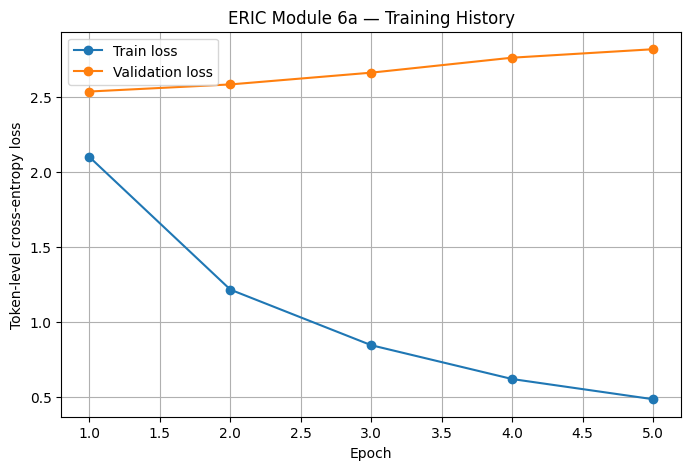

Best validation-loss epoch: 1
Best validation loss: 2.5385
Best checkpoint exists: True
Last checkpoint exists: True
Best checkpoint size (MB): 597.74


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import torch

history_df = pd.DataFrame(history)

display(history_df)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Token-level cross-entropy loss")
plt.title("ERIC Module 6a — Training History")
plt.legend()
plt.grid(True)
plt.show()

print("Best validation-loss epoch:", int(history_df["val_loss"].idxmin() + 1))
print("Best validation loss:", round(history_df["val_loss"].min(), 4))
print("Best checkpoint exists:", os.path.isfile(BEST_CHECKPOINT_PATH))
print("Last checkpoint exists:", os.path.isfile(LAST_CHECKPOINT_PATH))

if os.path.isfile(BEST_CHECKPOINT_PATH):
    print(
        "Best checkpoint size (MB):",
        round(os.path.getsize(BEST_CHECKPOINT_PATH) / (1024 ** 2), 2)
    )

assert os.path.isfile(BEST_CHECKPOINT_PATH), (
    "Best checkpoint not found. Check whether training completed."
)

## 11. Restore the best checkpoint and inspect example captions

The saved best checkpoint restores both encoder and decoder weights. The qualitative inspection cell displays images with generated captions and all five references.

Qualitative review matters because automatic metrics cannot fully capture factual correctness, useful detail, or hallucination. Look for generic captions, repeated phrases, missing scene elements, and unsupported objects. Use validation examples for model diagnosis; reserve the test set for final evaluation.


In [27]:
checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

encoder.load_state_dict(checkpoint["encoder_state_dict"])
decoder.load_state_dict(checkpoint["decoder_state_dict"])

encoder.eval()
decoder.eval()

print("Loaded checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint validation loss:", checkpoint["val_loss"])
print("Encoder and decoder restored successfully.")

Loaded checkpoint epoch: 1
Checkpoint validation loss: 2.538534105028052
Encoder and decoder restored successfully.


Loaded checkpoint from epoch: 1
Validation loss: 2.5385


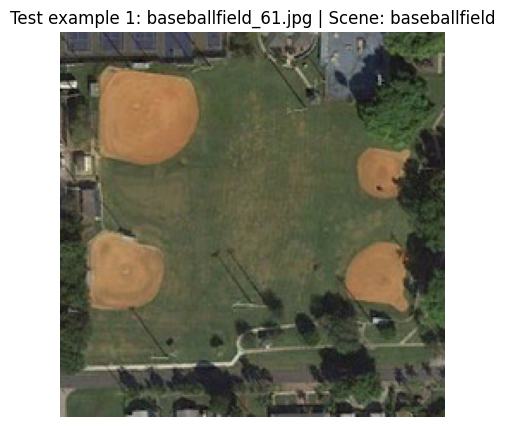

GENERATED CAPTION:
some green trees and some buildings are around a baseball field .

REFERENCE CAPTIONS:
1. there are four baseball fields in the four corner of the field .
2. there are four baseballfields of different size lying on the lawn  around which are some other
sports courts  trees  roads and houses .
3. four baseball field next to some tennis court and surrounded by some trees .
4. four baseballfields in different sizes are surrounded by several tennis courts and trees and a
row of houses .
5. several green trees and buildings are around four baseball fields in different sizes .




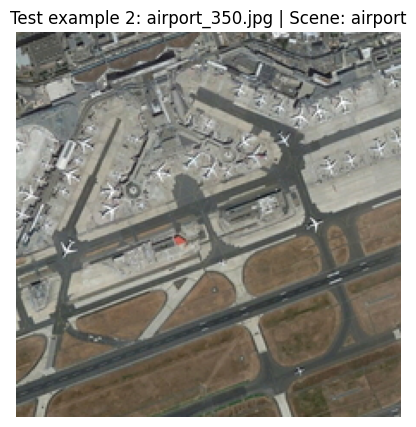

GENERATED CAPTION:
many planes are parked in an airport near some buildings with some green trees .

REFERENCE CAPTIONS:
1. there are many bare land near the airport .
2. many white planes were parked at the airport .
3. many white planes were parked at the airport .
4. there are many bare land near the airport .
5. there are many bare land near the airport .




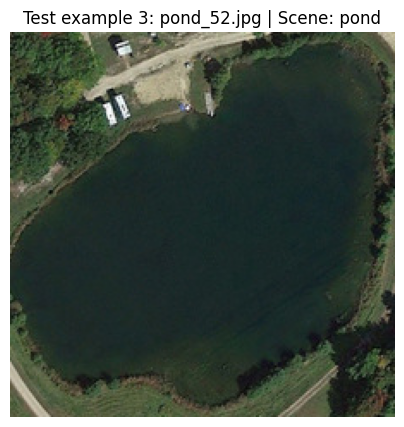

GENERATED CAPTION:
some green trees and some buildings are around an irregular pond .

REFERENCE CAPTIONS:
1. there is a lake in front of a white roof .
2. there are many tall trees around the lake .
3. there are many tall trees around the lake .
4. there is a lake in front of a white roof .
5. there is a lake in front of a white roof .




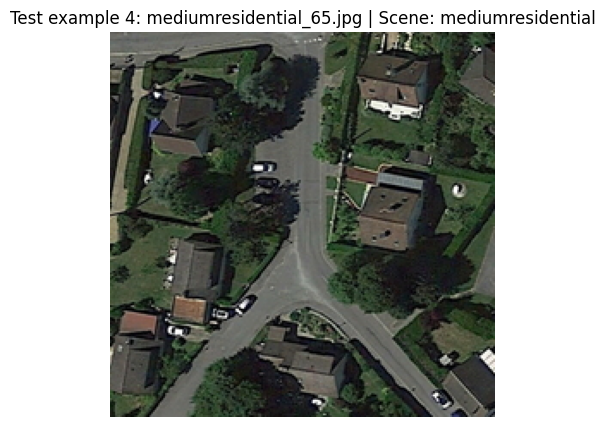

GENERATED CAPTION:
some buildings and green trees are in a medium residential area .

REFERENCE CAPTIONS:
1. a lambdoidal separates the residential which includes trees and many cars .
2. a lambdoidal separates the residential which includes trees and many cars .
3. a lambdoidal separates the residential which includes trees and many cars .
4. several cars are passing through this green serene neighborhood .
5. several buildings and some green trees are near a road .




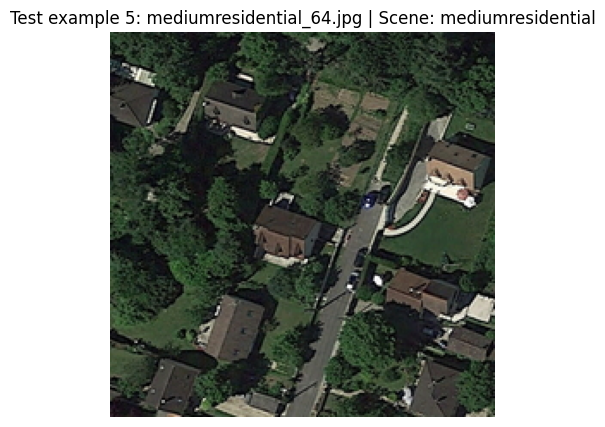

GENERATED CAPTION:
some buildings and green trees are in a medium residential area .

REFERENCE CAPTIONS:
1. there are many cars on the road .
2. on both sides of the road were rows of gray roofs .
3. on both sides of the road were rows of gray roofs .
4. there are many cars on the road .
5. there are many cars on the road .




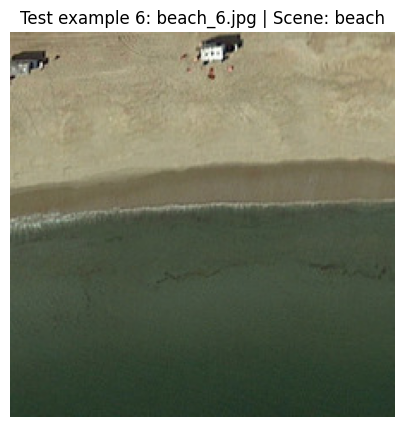

GENERATED CAPTION:
yellow beach is near a piece of green ocean .

REFERENCE CAPTIONS:
1. there is two buildings on the coast .
2. there is two buildings on the coast .
3. some flats are on the brown beach near the feculent sea .
4. two simple buildings are standing on this beach .
5. a piece of green ocean is near a yellow beach with two buildings .




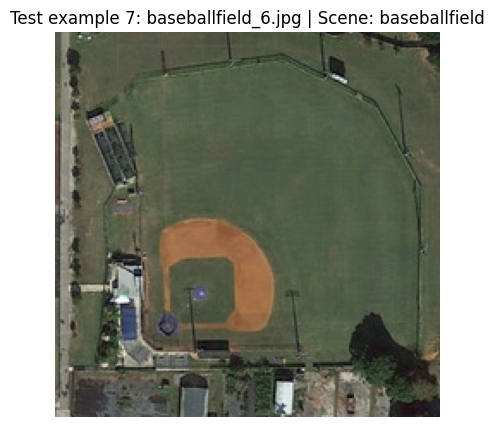

GENERATED CAPTION:
a baseball field is near some green trees .

REFERENCE CAPTIONS:
1. on the lawn is a baseball field and three other sports fields are across a street .
2. on the lawn is a baseball field and three other sports fields are across a street .
3. the polygon baseball field beside some footballfields .
4. in this picture we can see a large baseballfield alongside a basketball playground and two
tennis playground .
5. a baseball field is near several green trees .




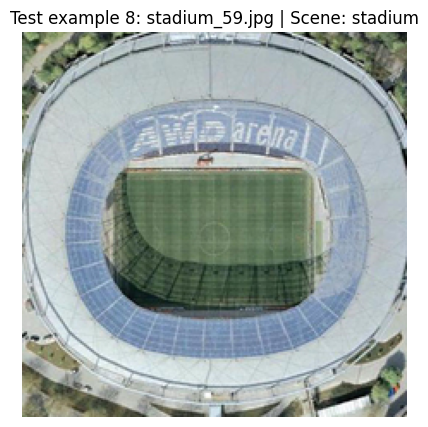

GENERATED CAPTION:
a football field is in the middle of the middle of the middle of the middle of the middle of the
middle .

REFERENCE CAPTIONS:
1. huge words of awd arena are writed int the blearchers of the stadium .
2. there is a bowl shaped stadium with blue stands on the square with trees and lawns .
3. there is a bowl shaped stadium with blue stands on the square with trees and lawns .
4. it is a huge soccer stadium whose roof spells awd arena on it .
5. many green trees are around a gray stadium with a football field in it .




In [28]:
import torch
import matplotlib.pyplot as plt
from PIL import Image
import textwrap
import random

# Load the best saved checkpoint
checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

encoder.load_state_dict(checkpoint["encoder_state_dict"])
decoder.load_state_dict(checkpoint["decoder_state_dict"])

encoder.eval()
decoder.eval()

print("Loaded checkpoint from epoch:", checkpoint["epoch"])
print("Validation loss:", round(checkpoint["val_loss"], 4))


def generate_caption(image_tensor, max_len=MAX_CAPTION_LEN):
    """
    Greedy autoregressive decoding.
    image_tensor: [1, 3, 224, 224]
    """
    image_tensor = image_tensor.to(device)

    with torch.inference_mode():
        with autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda"),
        ):
            image_features = encoder.forward_features(image_tensor)
            image_features = image_features[:, 1:, :]  # Remove CLS token

            generated = torch.tensor(
                [[BOS_IDX]], dtype=torch.long, device=device
            )

            for _ in range(max_len - 1):
                logits = decoder(image_features, generated)
                next_token_logits = logits[:, -1, :]

                # Prevent generation of special start/padding tokens
                next_token_logits[:, PAD_IDX] = float("-inf")
                next_token_logits[:, BOS_IDX] = float("-inf")

                next_token = next_token_logits.argmax(
                    dim=-1, keepdim=True
                )

                generated = torch.cat(
                    [generated, next_token], dim=1
                )

                if next_token.item() == EOS_IDX:
                    break

    return decode_caption(generated[0].tolist())


# Select test examples
NUM_EXAMPLES = 8
random.seed(SEED)

num_examples = min(NUM_EXAMPLES, len(test_records))
selected_records = random.sample(test_records, num_examples)

# Display each image and its generated caption + all five references
for idx, record in enumerate(selected_records, start=1):
    image_path = IMG_DIR / record["filename"]

    with Image.open(image_path) as img:
        original_image = img.convert("RGB").copy()

    image_tensor = image_transform(original_image).unsqueeze(0)
    predicted_caption = generate_caption(image_tensor)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.imshow(original_image)
    ax.axis("off")
    ax.set_title(
        f"Test example {idx}: {record['filename']} | Scene: {record['scene']}",
        fontsize=12,
    )
    plt.show()

    print("GENERATED CAPTION:")
    print(textwrap.fill(predicted_caption or "[EMPTY CAPTION]", width=100))

    print("\nREFERENCE CAPTIONS:")
    for ref_idx, reference in enumerate(record["captions"], start=1):
        print(f"{ref_idx}. {textwrap.fill(reference, width=96)}")

    print("\n" + "=" * 100 + "\n")

## 12. Comparable all-reference loss diagnostic

This section evaluates teacher-forced loss with the model in evaluation mode, using all five captions for every image in both train and validation sets. This is a diagnostic comparison, not the same protocol as the first-reference epoch-level validation loss used for checkpoint selection.

Recorded result:

| Diagnostic | Loss |
|---|---:|
| Training loss, evaluation mode, all references | 1.3423 |
| Validation loss, evaluation mode, all references | 1.9461 |
| Generalization gap (validation − training) | 0.6038 |

The positive gap indicates that the model predicts training captions more easily than validation captions. This supports the need to monitor generalization, though the loss gap alone does not establish the cause.


In [29]:
from torch.utils.data import DataLoader
from functools import partial
import torch

# Create deterministic loaders with the same five-caption treatment.
train_eval_dataset = RSICDTrainDataset(
    train_records, IMG_DIR, image_transform, MAX_CAPTION_LEN
)

val_eval_dataset = RSICDTrainDataset(
    val_records, IMG_DIR, image_transform, MAX_CAPTION_LEN
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=partial(collate_train, pad_idx=PAD_IDX),
)

val_eval_loader = DataLoader(
    val_eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=partial(collate_train, pad_idx=PAD_IDX),
)


@torch.inference_mode()
def evaluate_caption_loss(loader):
    encoder.eval()
    decoder.eval()

    total_loss = 0.0
    total_tokens = 0

    for images, captions in loader:
        images = images.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)

        caption_input = captions[:, :-1]
        targets = captions[:, 1:]

        with autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda"),
        ):
            image_features = encoder.forward_features(images)
            image_features = image_features[:, 1:, :]

            logits = decoder(image_features, caption_input)

            loss = criterion(
                logits.float().reshape(-1, logits.size(-1)),
                targets.reshape(-1),
            )

        valid_tokens = targets.ne(PAD_IDX).sum().item()
        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

    return total_loss / max(total_tokens, 1)


train_eval_loss = evaluate_caption_loss(train_eval_loader)
val_eval_loss = evaluate_caption_loss(val_eval_loader)

print(f"Train loss (eval mode, all captions): {train_eval_loss:.4f}")
print(f"Validation loss (eval mode, all captions): {val_eval_loss:.4f}")
print(f"Generalization gap: {val_eval_loss - train_eval_loss:.4f}")

Train loss (eval mode, all captions): 1.3462
Validation loss (eval mode, all captions): 1.9501
Generalization gap: 0.6039


## 13. Generate captions for validation and test sets

The best checkpoint is loaded before generation. Greedy autoregressive decoding repeatedly predicts the most likely next token until `<eos>` is generated or the maximum sequence length is reached.

For every image, the notebook stores:
- filename and scene class,
- generated caption,
- all five human-written reference captions.

The predictions are saved to JSON so metric calculations can be audited and repeated without retraining. Validation and test results are generated separately; the test set must not be used to tune the model.


In [30]:
import os
import json
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

# Load the best checkpoint if it is not already loaded
checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

encoder.load_state_dict(checkpoint["encoder_state_dict"])
decoder.load_state_dict(checkpoint["decoder_state_dict"])

encoder.eval()
decoder.eval()

print("Loaded best checkpoint.")
print("Best epoch:", checkpoint.get("epoch", "Not stored"))
print("Best validation loss:", checkpoint.get("val_loss", "Not stored"))

Loaded best checkpoint.
Best epoch: 1
Best validation loss: 2.538534105028052


In [31]:
import gc

OUTPUT_DIR = "/kaggle/working/ERIC_Module6a"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def collect_caption_results(records, split_name):
    results = []

    encoder.eval()
    decoder.eval()

    for record in tqdm(records, desc=f"Generating {split_name} captions"):
        filename = record["filename"]
        image_path = os.path.join(IMG_DIR, filename)

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image_tensor = image_transform(image).unsqueeze(0)

        # Uses your existing Module 6a generation function
        prediction = generate_caption(image_tensor)

        results.append({
            "filename": filename,
            "scene": record.get("scene", ""),
            "prediction": prediction,
            "references": record["captions"]
        })

    print(f"{split_name}: generated {len(results)} captions.")
    return results


# Validation results
val_results = collect_caption_results(
    val_records,
    "validation"
)

# Test results
test_results = collect_caption_results(
    test_records,
    "test"
)

# Save complete results, including all references
with open(os.path.join(OUTPUT_DIR, "validation_predictions.json"), "w") as f:
    json.dump(val_results, f, indent=2, ensure_ascii=False)

with open(os.path.join(OUTPUT_DIR, "test_predictions.json"), "w") as f:
    json.dump(test_results, f, indent=2, ensure_ascii=False)

print("Saved validation and test predictions.")

Generating validation captions:   0%|          | 0/281 [00:00<?, ?it/s]

validation: generated 281 captions.


Generating test captions:   0%|          | 0/281 [00:00<?, ?it/s]

test: generated 281 captions.
Saved validation and test predictions.


## 14. Evaluation metrics

All metrics compare one generated caption per image against the image's five reference captions.

- **BLEU-1 to BLEU-4:** n-gram precision-based metrics, from individual-word overlap through four-word sequences. Higher-order BLEU is more sensitive to phrase-level matching.
- **METEOR:** compares aligned tokens and accounts for stemming and synonym matching through the metric implementation.
- **ROUGE-L:** measures overlap based on the longest common subsequence.
- **CIDEr:** measures consensus with reference captions and weights informative n-grams.

These metrics measure textual similarity to references; they are not classification accuracy and do not fully measure factual correctness. Scores should only be compared across modules when splits, references, tokenization, decoding, and metric implementations are held consistent.

The implementation computes BLEU-1–4, METEOR, ROUGE-L, and CIDEr, then saves the aggregate metrics and per-image predictions.


In [32]:
!pip -q install nltk pycocoevalcap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 18.9 MB/s eta 0:00:0000:0100:01


In [33]:
import nltk

nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

from nltk.translate.meteor_score import meteor_score
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider

## 15. Final results — Module 6a

The following table records the generated-caption evaluation from the current run. Validation and test each contain 281 images.

| Split | Images | BLEU-1 | BLEU-2 | BLEU-3 | BLEU-4 | METEOR | ROUGE-L | CIDEr |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Validation | 281 | 0.7478 | 0.6103 | 0.5061 | 0.4325 | 0.6802 | 0.6322 | 2.0427 |
| Test | 281 | 0.6531 | 0.4542 | 0.3328 | 0.2607 | 0.4462 | 0.4735 | 0.5776 |

### Interpretation

1. Every reported metric is lower on the test set than on validation.
2. BLEU-4 drops from 0.4325 to 0.2607, indicating weaker four-word sequence overlap with test references.
3. CIDEr drops from 2.0427 to 0.5776, showing a substantial reduction in agreement with the reference-caption consensus.
4. Together with the training history, this pattern is consistent with overfitting and/or a difference in difficulty between the validation and test images. These scores alone cannot distinguish those explanations.

**Reporting status:** these results establish the current image-only baseline. The performance gap should be reported as a limitation; do not describe the model as having strong generalization without further evidence. Ensure all later modules use the same evaluation implementation and official splits.


In [34]:
def evaluate_caption_results(results, split_name):
    references = {}
    hypotheses = {}

    for i, result in enumerate(results):
        # Unique keys avoid accidental filename collisions
        image_key = f"{i}_{result['filename']}"

        references[image_key] = result["references"]
        hypotheses[image_key] = [result["prediction"]]

    if not references:
        raise ValueError(f"No results available for {split_name}.")

    # BLEU-1 to BLEU-4
    bleu_score, _ = Bleu(4).compute_score(
        references, hypotheses
    )

    # METEOR: average across images
    meteor_scores = []

    for key in references:
        ref_tokens = [
            ref.lower().split()
            for ref in references[key]
        ]
        pred_tokens = hypotheses[key][0].lower().split()

        meteor_scores.append(
            meteor_score(ref_tokens, pred_tokens)
        )

    meteor_value = sum(meteor_scores) / len(meteor_scores)

    # ROUGE-L
    rouge_score, _ = Rouge().compute_score(
        references, hypotheses
    )

    # CIDEr
    cider_score, _ = Cider().compute_score(
        references, hypotheses
    )

    metrics = {
        "Split": split_name,
        "Images": len(results),
        "BLEU-1": float(bleu_score[0]),
        "BLEU-2": float(bleu_score[1]),
        "BLEU-3": float(bleu_score[2]),
        "BLEU-4": float(bleu_score[3]),
        "METEOR": float(meteor_value),
        "ROUGE-L": float(rouge_score),
        "CIDEr": float(cider_score)
    }

    print(f"\n{'=' * 52}")
    print(f"{split_name.upper()} CAPTIONING RESULTS")
    print("=" * 52)

    for metric, value in metrics.items():
        if metric != "Split":
            print(f"{metric:12s}: {value:.4f}" if isinstance(value, float)
                  else f"{metric:12s}: {value}")

    return metrics


val_metrics = evaluate_caption_results(
    val_results, "validation"
)

test_metrics = evaluate_caption_results(
    test_results, "test"
)

metrics_df = pd.DataFrame([val_metrics, test_metrics])
display(metrics_df)

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "caption_metrics.csv"),
    index=False
)

with open(os.path.join(OUTPUT_DIR, "caption_metrics.json"), "w") as f:
    json.dump(
        {"validation": val_metrics, "test": test_metrics},
        f,
        indent=2
    )

print("Saved caption_metrics.csv and caption_metrics.json.")

{'testlen': 3033, 'reflen': 2902, 'guess': [3033, 2752, 2471, 2190], 'correct': [2327, 1461, 912, 614]}
ratio: 1.0451412818742092

VALIDATION CAPTIONING RESULTS
Images      : 281
BLEU-1      : 0.7672
BLEU-2      : 0.6382
BLEU-3      : 0.5317
BLEU-4      : 0.4531
METEOR      : 0.7131
ROUGE-L     : 0.6579
CIDEr       : 2.2709
{'testlen': 3021, 'reflen': 3132, 'guess': [3021, 2740, 2459, 2178], 'correct': [2013, 907, 481, 287]}
ratio: 0.9645593869728721

TEST CAPTIONING RESULTS
Images      : 281
BLEU-1      : 0.6423
BLEU-2      : 0.4527
BLEU-3      : 0.3381
BLEU-4      : 0.2647
METEOR      : 0.4496
ROUGE-L     : 0.4715
CIDEr       : 0.6241


,Split,Images,BLEU-1,BLEU-2,BLEU-3,BLEU-4,METEOR,ROUGE-L,CIDEr
0,validation,281,0.767227,0.638209,0.531720,0.453099,0.713133,0.657928,2.270923
1,test,281,0.642297,0.452708,0.338082,0.264687,0.449627,0.471516,0.624118


Saved caption_metrics.csv and caption_metrics.json.


In [35]:
def results_to_dataframe(results, split_name):
    rows = []

    for result in results:
        row = {
            "split": split_name,
            "filename": result["filename"],
            "scene": result.get("scene", ""),
            "prediction": result["prediction"]
        }

        for i, reference in enumerate(result["references"], start=1):
            row[f"reference_{i}"] = reference

        rows.append(row)

    return pd.DataFrame(rows)


val_df = results_to_dataframe(val_results, "validation")
test_df = results_to_dataframe(test_results, "test")

val_df.to_csv(
    os.path.join(OUTPUT_DIR, "validation_image_results.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_image_results.csv"),
    index=False
)

display(test_df.head(10))

print("All evaluation files saved to:", OUTPUT_DIR)

,split,filename,scene,prediction,reference_1,reference_2,reference_3,reference_4,reference_5
0,test,airport_49.jpg,airport,some planes are parked in an airport .,some trees were planted around the airport .,there are many grey roof houses around the air...,the airplanes seems very small compared the bi...,the airplanes seems very small compared the bi...,some trees were planted around the airport .
1,test,airport_36.jpg,airport,some planes are parked in an airport .,there is a parking apron with planes parked on...,there is a parking apron with planes parked on...,the airport consisted of some blue blocks with...,the termial building separats the landside and...,several planes are parked in an airport near s...
2,test,airport_52.jpg,airport,some planes are in an airport near some green ...,there is a wide road in front of the airport .,there is a house with a red roof on the airport .,there is a house with a red roof on the airport .,there is a wide road in front of the airport .,there is a wide road in front of the airport .
3,test,airport_50.jpg,airport,some planes are in an airport near some planes .,there are a lot of bare land around the airport .,the land in front of the airport grows large l...,there is a row of red roofed houses near the a...,the airport has a lot of white planes .,there is a row of red roofed houses near the a...
4,test,airport_39.jpg,airport,some planes are in an airport near some green ...,the narrow terminal building between some squa...,the narrow terminal building between some squa...,some planes stop in order in the red airport .,the long striped termial building sits alongsi...,a line of white planes are near a building in ...
5,test,airport_353.jpg,airport,some planes are parked near a terminal in an a...,the two drop shaped terminal buildings are sur...,the two drop shaped terminal buildings are sur...,some planes stop in the drop shaped terminal ...,the c shaped termial building sits on the apro...,some planes are near a building in an airport .
6,test,airport_56.jpg,airport,some planes are near a terminal in an airport .,several airplanes with different size are in t...,several airplanes with different size are in t...,several airplanes with different size are in t...,several airplanes with different size are in t...,several airplanes with different size are in t...
7,test,airport_38.jpg,airport,some planes are in an airport near some green ...,there is a parking apron with an aeroplane lyi...,there is a parking apron with an aeroplane lyi...,a single airport and a cross runway located in...,a simple termimal building sits besides the ap...,a white plane is near a building while a line ...
8,test,airport_40.jpg,airport,some planes are in an airport near some buildi...,an airport was built in this area .,there are many houses near the airport .,several airplanes are in a big airport .,several airplanes are in a big airport .,an airport was built in this area .
9,test,airport_45.jpg,airport,some planes are near a terminal in an airport .,on the parking apron there is a semi circular ...,on the parking apron there is a semi circle bu...,a prolate ellipse boarding gate next to the pa...,a striped termial building sits on a large apr...,several planes are near a building in an airpo...


All evaluation files saved to: /kaggle/working/ERIC_Module6a


In [36]:
def show_caption_examples(results, n=10):
    for result in results[:n]:
        print("=" * 90)
        print("Image:", result["filename"])
        print("Scene:", result.get("scene", ""))
        print("\nGenerated:")
        print(result["prediction"])
        print("\nReferences:")

        for i, reference in enumerate(result["references"], start=1):
            print(f"{i}. {reference}")

# Use validation examples while diagnosing or tuning the model
show_caption_examples(val_results, n=10)

Image: airport_65.jpg
Scene: airport

Generated:
some planes are in an airport .

References:
1. the ploygon terminal building is built near road and other buildings  on the other side of which is tarmac and runways .
2. the ploygon terminal building is built near road and other buildings  on the other side of which is tarmac and runways .
3. the alternation runway next to a bright blue parking aroneng .
4. a dazzling apron is surrounded by the termial building and six block of houses and two runway .
5. a plane is on the runway while other two planes are near some buildings and green plants .
Image: airport_62.jpg
Scene: airport

Generated:
some planes are parked near a terminal in an airport .

References:
1. many white planes are parked at the airport .
2. a highway is built next to the airport .
3. a highway is built next to the airport .
4. many white planes are parked at the airport .
5. many white planes are parked at the airport .
Image: airport_80.jpg
Scene: airport

Generated

## 16. Saved outputs and artifacts

The notebook writes the following artifacts under `/kaggle/working/ERIC_Module6a`:

| Artifact | Contents |
|---|---|
| `module6a_best.pt` | Encoder/decoder weights from the best validation-loss epoch, vocabulary, configuration, and training history |
| `module6a_last.pt` | Weights from the final training epoch |
| `validation_predictions.json` | Validation predictions with all five references |
| `test_predictions.json` | Test predictions with all five references |
| `caption_metrics.csv` | Aggregate validation and test metric table |
| `caption_metrics.json` | Aggregate metrics in JSON format |
| `validation_image_results.csv` | Per-image validation prediction and references |
| `test_image_results.csv` | Per-image test prediction and references |

For reproducibility, retain the notebook, the best checkpoint, the vocabulary/tokenizer configuration, and these evaluation artifacts together.


## 17. Conclusion and transition to Module 6b

Module 6a implements an image-only captioning baseline using an ImageNet-pretrained ViT-Base/16 encoder and a Transformer decoder trained from scratch. The best checkpoint was selected by validation loss, and caption generation was evaluated with BLEU-1–4, METEOR, ROUGE-L, and CIDEr against five references per image.

The test results are below validation across all metrics, so the baseline should be treated as a completed but imperfect reference point. The next experiment, **Module 6b**, can test raster-only captioning. For a valid comparison, keep the same official image splits, references, evaluation metrics, and reporting conventions wherever the input modality permits.
